# Intro

This notebook tests the functions of single unit plotting to plot one session's rates and rasters

---
# Setup

In [1]:
##% imports
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from time import time

from popy.io_tools import load_behavior, load_neural_data
from popy.behavior_data_tools import add_foraging_value, drop_time_fields, add_RL_values, add_switch_info, add_history_of_feedback
from popy.neural_data_tools import *
from popy.plotting.plotting_tools import plot_keypoints


from popy.config import COLORS, value_gradient
# fontsizes 8
plt.rcParams.update({'font.size': 8})


/home/uzsombi/.config/matplotlib is not a writable directory
Matplotlib created a temporary cache directory at /tmp/matplotlib-ouhu6_er because there was an issue with the default path (/home/uzsombi/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


In [2]:
##% data tools
def get_data(monkey, session, mode='full_trial', n_extra_trials=(0, 0), unit_of_interest=None):
    #neural_data = get_data(monkey, session, n_extra_trials=n_extra_trials)

    # get behavior data
    behav = load_behavior(monkey, session)

    behav['feedback_t-1'] = behav['feedback'].shift(1)  # shift the feedback by 1
    behav['feedback_t-2'] = behav['feedback'].shift(2)  # shift the feedback by 1
    behav['feedback_t-3'] = behav['feedback'].shift(3)  # shift the feedback by 1
    behav['feedback_t-4'] = behav['feedback'].shift(4)  # shift the feedback by 1
    behav['feedback_t-5'] = behav['feedback'].shift(5)  # shift the feedback by 1
    behav['feedback_t-6'] = behav['feedback'].shift(6)  # shift the feedback by 1
    behav['feedback_t-7'] = behav['feedback'].shift(7)  # shift the feedback by 1
    behav['feedback_t-8'] = behav['feedback'].shift(8)  # shift the feedback by 1

    # histroy of feedback column
    behav = add_history_of_feedback(behav, num_trials=2, one_column=True)  # add history of feedback

    # remove interrupted trials (fb is nan)
    behav = behav.dropna()

    # shift the value function by 1
    behav = drop_time_fields(behav)  

    # get neural data
    neural_data = load_neural_data(monkey, session, hz=1000)  # load neural data

    if unit_of_interest is not None:
        neural_data = neural_data.sel(unit=[unit_of_interest])  # select the unit of interest
    else:
        neural_data = remove_trunctuated_neurons(neural_data, mode='set_nan', delay_limit=20, print_usr_msg=True)  # set indices to nan

    neural_data = add_firing_rates(neural_data, 'count')  # add firing gauss
    neural_data = downsample_time(neural_data, 100)  # downsample neural data
    #neural_data = time_normalize_session(neural_data)  # normalize neural data in time
    
    # build dataset
    if mode == 'full_trial':
        neural_dataset = build_trial_dataset(neural_data, mode='full_trial', n_extra_trials=n_extra_trials)
    elif mode == 'centering':
        neural_dataset = build_trial_dataset(neural_data, mode='centering', center_on_epoch_start=5, center_window=(-3, 3))

    print(f'Built dataset, shape:')
    neural_dataset = merge_behavior(neural_dataset, behav)  # merge behavior and neural data

    return neural_data, neural_dataset
    
        
def add_mixed_coord(neural_data_original, groupped_by):
    '''
    Removes all the coords from the neural_data except the trial_id, and adds a new coord along the trials dimension. Only the 
    coords to plot will rest in the neural_data.

    E.g. groupped_by = 'value * target' -> under each target, look at the value levels.
    
    '''
    neural_data = neural_data_original.copy()
    
    groupped_by = groupped_by.split(' * ')

    if len(groupped_by) == 1:
        primary_labels = neural_data.coords[groupped_by[0]].data  # e.g. a vector of the value levels per trial
        neural_data.coords[f'*{groupped_by[0]}'] = ('trial_id', primary_labels)
        return neural_data
        
    elif len(groupped_by) == 2:
        '''
        E.g. groupped_by = 'value * target' -> under each target, look at the value levels.
        '''    
        
        # get the 
        primary_labels = neural_data.coords[groupped_by[0]].data  # e.g. a vector of the value levels per trial
        secondary_labels = neural_data.coords[groupped_by[1]].data  # e.g. a vector of the selected targets per trial
                
        # add new coord along the trials dimension
        unique_secondary_labels = np.unique(secondary_labels)  # e.g. the unique targets
        unique_secondary_labels = unique_secondary_labels[~np.isnan(unique_secondary_labels)]  # remove nans
        for secondary_label in unique_secondary_labels:
            coord_name = f'*{groupped_by[0]} | {groupped_by[1]}={str(secondary_label)}'  # e.g. target_1_value
            coord_values = [primary if secondary == secondary_label else np.nan for primary, secondary in zip(primary_labels, secondary_labels) ]
            neural_data.coords[coord_name] = ('trial_id', coord_values)
            print(f'Added coord {coord_name}, length: {len(coord_values)}')
        
    return neural_data
    
        


In [3]:
##% plotting tools

'''COLORS_value= [
    '#779ECC',  # Dark Pastel Blue
    '#9FC0DE',  # Pale Cerulean
    '#F2C894',  # Peach-Orange
    '#FFB347',  # Pastel Orange
    '#FF985A'   # Atomic Tangerine
]

COLORS_feedback = [
    'tab:red',
    'tab:green',
]
'''

def plot_spike_trains(neural_data, monkey, session):
    plt.imshow(neural_data.spike_trains, aspect='auto', cmap='Grays', interpolation='none')
    ylabel = [f'{unit}' for unit in neural_data.unit.values]
    xlabel = neural_data.time.values
    plt.yticks(np.arange(len(ylabel)), ylabel, fontsize=5)
    #plt.xticks(np.arange(0, len(xlabel), 100000), xlabel[::100000])

    # add lables and legend: white horizontal bar is no recording, black is recording
    plt.plot([0, 0], [0, 0], color='black', label='Recording', linewidth=5)
    plt.plot([0, 0], [0, 0], color='white', label='No recording', linewidth=5)
    plt.legend(loc='upper right')

    plt.grid(alpha=.2)

    plt.xlabel('Time (ms)')
    plt.ylabel('Neurons')
    plt.title(f'{monkey}_{session}')
    plt.show()

def plot_rates_with_raster(
    neural_data_original, 
    unit_name, 
    mode='full_trial',  # 'full_trial' or 'centering'
    n_extra_trials=(0, 0),  # number of extra trials to plot (in case of full_trial)
    title=None,
    time_window=None,  # time window to plot (relative to the time of the data)
    color_palette=None,  # color palette to use, 'feedback' or 'value'
    show_raster=True,
    paper_format=False,  # use paper format
    ):    
    '''
    Plot the raster plot and the firing rate of a unit, for each value level of the coord_names.
    
    Parameters
    ----------
    neural_data : xarray.Dataset
        The neural data.
    unit_name : str
        The name of the unit to plot.
    n_extra_trials : touple, optional
        The number of extra trials to plot. The default is (0, 0).
    title : str, optional
        The title of the plot. The default is None.
    time_window : tuple, optional
        The time window to plot. The default is None.

    Returns
    ------- 
    fig : matplotlib.figure.Figure
        The figure.
    axs : matplotlib.axes.Axes
        The axes.
    '''

    neural_data = neural_data_original.copy()
    neural_data = neural_data.sel({'unit': unit_name})  # select the unit of interest

    # get the coord names of interest and determine the number of plots to make
    coord_names = [coord_name for coord_name in neural_data.coords if coord_name[0] == '*']  # get the coord names of interest
    n_plots = len(coord_names)
    
    # Create figure and axes with no space between rows
    if paper_format:
        # fontsize 8
        plt.rcParams.update({'font.size': 8})  # set fontsize to 8
        h, w = 1, 1.5 * n_plots  # 3 cm height, 3 cm width per plot
        fig = plt.figure(figsize=(w, h))
    else:
        h, w = 3, 3*n_plots
        fig = plt.figure(figsize=(w, h))
    
    gs = fig.add_gridspec(2, n_plots, height_ratios=[1, 1], hspace=0)

    # Create axes arrays with shared axes
    axs = [[None for j in range(n_plots)] for i in range(2)]
    
    # First create the leftmost column
    axs[0][0] = fig.add_subplot(gs[0, 0])  # Top left
    axs[1][0] = fig.add_subplot(gs[1, 0], sharex=axs[0][0])  # Bottom left
    plt.setp(axs[0][0].get_xticklabels(), visible=False)  # Hide only the tick labels, keep ticks

    # Then create the rest sharing both x and y axes
    for j in range(1, n_plots):
        axs[0][j] = fig.add_subplot(gs[0, j], sharex=axs[0][0], sharey=axs[0][0])  # Top row
        axs[1][j] = fig.add_subplot(gs[1, j], sharex=axs[0][0], sharey=axs[1][0])  # Bottom row
        plt.setp(axs[0][j].get_xticklabels(), visible=False)  # Hide only the tick labels, keep ticks

    if not title is None:
        fig.suptitle(title, style='italic')

    for i, coord_name in enumerate(coord_names):
        # get the variable and the conditions
        variable = coord_name.split(' | ')[0][1:]
        condition = coord_name.split(' | ')[1] if len(coord_name.split(' | ')) > 1 else None

        unique_labels = np.unique(neural_data[coord_name].data)  # get the unique labels of all of the coords of interest
        unique_labels = unique_labels[~np.isnan(unique_labels)]  # remove nans
        
        if variable == 'feedback':
            COLORS_temp = COLORS
        elif variable == 'stay_value':
            COLORS_temp = value_gradient(len(unique_labels))
        elif variable == 'history_of_feedback':
            # n levels dark colors, low values are negative colrs, high are positive colors
            n = len(unique_labels)
            COLORS_temp = plt.cm.RdYlGn(np.linspace(0, 1, n))  # get the colors from the colormap
        else:
            COLORS_temp = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple', 'tab:brown', 'tab:pink', 'tab:gray', 'tab:olive', 'tab:cyan']

        colors = {str(label): COLORS_temp[i] for i, label in enumerate(unique_labels)}  # color for each value level

        # prepare the data (sort trials by the coord_name, drop trials with nan labels)
        neural_data_temp = _prepare_data(neural_data, coord_name)

        time_vector = neural_data_temp.coords['time'].data  # get the time vector and the trial labels

        # plot raster with extent of x=time_vector and y=trial_labels
        ax_raster = axs[0][i] if n_plots > 1 else axs[0][0]

        
        # Plot colored spikes
        if show_raster:
            # Convert spike trains to x,y coordinates
            spikes = np.where(neural_data_temp.spike_trains)
            trial_ids = spikes[0]
            spike_times = time_vector[spikes[1]]

            # Get colors for each spike based on trial type
            trial_colors = [colors[str(neural_data_temp[coord_name].sel(trial_id=neural_data_temp.trial_id.data[tid]).data)] for tid in trial_ids]  # get the color of the trial

            ax_raster.scatter(spike_times, trial_ids, marker='|', c=trial_colors, s=8, linewidth=0.8)
        else:
            # remove subplot if no raster is shown
            axs[0][i].remove()

        # settings
        if not paper_format:
            if condition is None:
                ax_raster.set_title(f'CODING OF: {variable}')
            else:
                ax_raster.set_title(f'CODING OF: {variable}' + f'\nCONDITION: {condition}')
            
        ax_raster.set_ylabel('')
        '''ax_raster.set_xlabel('')  # remove x label from the raster plot
        ax_raster.set_xticks([])  # remove y ticks'''
        ax_raster.set_yticks([])  # remove y ticks
        #ax_raster.legend(title=f'{coord_name.split("--")[0][1:]}', loc='center left', bbox_to_anchor=(1, 0.5))
        ax_raster.spines['bottom'].set_visible(False)

        # plot firing rate (that is the mean spike count) by value level
        ax_rate = axs[1][i] if n_plots > 1 else axs[1][0]
        unique_labels_temp = np.unique(neural_data_temp[coord_name].data)  # set background color based on value level
        for label_temp in unique_labels_temp:
            curr_coord_ids = np.where(neural_data_temp[coord_name].data == label_temp)[0]  # get the non-nan indices
            curr_coord_trials = neural_data_temp.trial_id.data[curr_coord_ids]
            neural_data_currvalue = neural_data_temp.sel({'trial_id': curr_coord_trials})  # further select only the interesting units
            # rolling window spike count mean
            mean_rate = np.mean(neural_data_currvalue.spike_counts, axis=0)

            ax_rate.plot(time_vector, mean_rate, label=f'{label_temp}', color=colors[str(label_temp)])
            
        if not paper_format:
            ax_rate.set_ylabel('Mean spike count')
            ax_rate.set_xlabel('Time from feedback (s)')
            ax_rate.legend(title=variable, frameon=False, loc='upper right')
        # settings
        for ax in [ax_raster, ax_rate]:
            if mode == 'full_trial':
                plot_keypoints(ax, n_extra_trials=n_extra_trials)  # plot the extra trials
                ax.grid(axis='x', alpha=.8, color='grey', linestyle='--')
            elif mode == 'centering':
                ax.axvline(0, color='black', lw=.7)  # plot the centering line
    

            if time_window is None:
                ax.set_xlim(time_vector[0], time_vector[-1])
            else:
                ax.set_xlim(*time_window)
            # remove spines
            for spine in ['right', 'top']:
                ax.spines[spine].set_visible(False)

    if not paper_format:    
        plt.tight_layout()

    return fig, axs


def _prepare_data(neural_data, coord_name):
        neural_data_temp = neural_data.copy()
        
        # get only the trials where the coord_name is not nan, and sort them
        non_nan_coord_ids = np.where(~np.isnan(neural_data_temp[coord_name].data))[0]  # get the non-nan indices
        non_nan_coord_trials = neural_data_temp.trial_id.data[non_nan_coord_ids]  # get the non-nan trials
        non_nan_coord_labels = neural_data_temp[coord_name].data[non_nan_coord_ids]  # get the non-nan labels
        non_nan_coord_trials = non_nan_coord_trials[np.argsort(non_nan_coord_labels)]  # sort the trials by the labels
        neural_data_temp = neural_data_temp.sel({'trial_id': non_nan_coord_trials})  # remove nan values (nan coordinates) and sort the trials by the labels

        # get only tials where the neural activity has no nan values - THIS SHOULD BE DONE BEFORE PASSING THE DATA TO THE PLOTTING FUNCTION
        """non_nan_ids = np.where(~np.isnan(neural_data_temp.spike_trains.data).all(axis=1))[0]
        non_nan_trials = neural_data_temp.trial_id.data[non_nan_ids]
        neural_data_temp = neural_data_temp.sel({'trial_id': non_nan_trials})"""  # remove nan values (nan neural activity)
    
        return neural_data_temp

---
# Load data

In [4]:
monkey, session = 'ka', '020622'
n_extra_trials = (0, 0)

In [5]:
neural_data, neural_dataset = get_data(monkey, session, mode='centering', unit_of_interest='MCC_06_01')  # get the neural data and the dataset

neural_dataset

Built dataset, shape:


<xarray.Dataset>
Dimensions:              (unit: 1, trial_id: 333, time: 600)
Coordinates: (12/25)
  * unit                 (unit) object 'MCC_06_01'
    unit_id_original     (unit) int64 72
    channel              (unit) int64 6
    monkey               (unit) object 'ka'
    session              (unit) object '020622'
    area                 (unit) object 'MCC'
    ...                   ...
    feedback_t-6         (trial_id) float64 0.0 1.0 0.0 1.0 ... 1.0 1.0 0.0 1.0
    feedback_t-7         (trial_id) float64 1.0 0.0 1.0 0.0 ... 1.0 1.0 1.0 0.0
    feedback_t-8         (trial_id) float64 1.0 1.0 0.0 1.0 ... 1.0 1.0 1.0 1.0
    T_1                  (trial_id) float64 2.0 2.0 2.0 2.0 ... 3.0 3.0 3.0 3.0
    T_2                  (trial_id) float64 2.0 2.0 2.0 2.0 ... 3.0 3.0 3.0 3.0
    history_of_feedback  (trial_id) float64 1.0 2.0 3.0 1.0 ... 3.0 1.0 2.0 1.0
Data variables:
    spike_trains         (trial_id, unit, time) float64 0.0 0.0 0.0 ... 0.0 0.0
    spike_counts         (trial_id, unit, time) float32 0.0 0.0 0.0 ... 0.0 0.0
Attributes:
    bin_size:  0.01

---
# Plot raster by value level as condition

In [6]:
#variable_of_interest = 'feedback'
neural_data_proc = neural_dataset.copy()
neural_data_proc = add_mixed_coord(neural_data_proc, 'history_of_feedback')
neural_data_proc

<xarray.Dataset>
Dimensions:               (unit: 1, trial_id: 333, time: 600)
Coordinates: (12/26)
  * unit                  (unit) object 'MCC_06_01'
    unit_id_original      (unit) int64 72
    channel               (unit) int64 6
    monkey                (unit) object 'ka'
    session               (unit) object '020622'
    area                  (unit) object 'MCC'
    ...                    ...
    feedback_t-7          (trial_id) float64 1.0 0.0 1.0 0.0 ... 1.0 1.0 1.0 0.0
    feedback_t-8          (trial_id) float64 1.0 1.0 0.0 1.0 ... 1.0 1.0 1.0 1.0
    T_1                   (trial_id) float64 2.0 2.0 2.0 2.0 ... 3.0 3.0 3.0 3.0
    T_2                   (trial_id) float64 2.0 2.0 2.0 2.0 ... 3.0 3.0 3.0 3.0
    history_of_feedback   (trial_id) float64 1.0 2.0 3.0 1.0 ... 3.0 1.0 2.0 1.0
    *history_of_feedback  (trial_id) float64 1.0 2.0 3.0 1.0 ... 3.0 1.0 2.0 1.0
Data variables:
    spike_trains          (trial_id, unit, time) float64 0.0 0.0 0.0 ... 0.0 0.0
    spike_counts          (trial_id, unit, time) float32 0.0 0.0 0.0 ... 0.0 0.0
Attributes:
    bin_size:  0.01

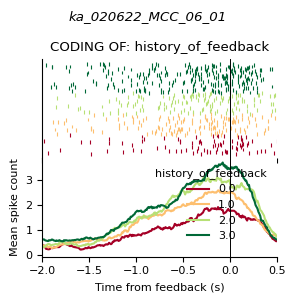

In [13]:
#unit_name = neural_data_proc.unit.data[-11]  # get the first unit as an example
unit_name = 'MCC_06_01'  # get the first unit as an example

#for unit_name in neural_data_proc.unit.data:

title = f'{neural_data_proc.coords["monkey"].data[0]}_{neural_data_proc.coords["session"].data[0]}_{unit_name}'
fig, axs = plot_rates_with_raster(
    neural_data_proc, 
    unit_name, 
    mode='centering',
    #n_extra_trials=n_extra_trials, 
    title=title,
    time_window=(-2, .5),
    show_raster=True,
    paper_format=False,  # use paper format
    )
    
# save the figure in svg, 300 dpi
fig.savefig(
    f'raster_vs_history_of_feedback.svg',
    dpi=300,
    bbox_inches='tight',
    transparent=True
    )
    
plt.show()
plt.close()


In [8]:
# lets plot the neural activity (y axis) against history level (x axis) for each value level (color).
# its a boxplot with scattered points, and the mean and std of the neural activity for each history level and value level.
# we are interested in the neural activity in the time window -.2s

t_interest = -.1  # time of interest
y = neural_data_proc.spike_counts.sel(time=t_interest, method='nearest').data.squeeze()
x = neural_data_proc.coords['history_of_feedback'].data

print(x.shape, y.shape)

(333,) (333,)


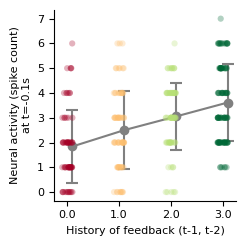

Level 0.0: mean rate = 1.84 ± 1.47 (std)
Level 1.0: mean rate = 2.50 ± 1.58 (std)
Level 2.0: mean rate = 3.05 ± 1.37 (std)
Level 3.0: mean rate = 3.61 ± 1.56 (std)


In [12]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# 1. Calculate summary statistics (mean and std) per history level
levels = np.unique(x)
means = [np.mean(y[x == level]) for level in levels]
stds = [np.std(y[x == level]) for level in levels]

fig, ax = plt.subplots(figsize=(2.5, 2.5))

# 2. Add jittered scatter points for raw data
rng = np.random.default_rng(0)
jitter = rng.uniform(-0.1, 0.1, size=x.size)
# Map x categories to numerical indices 0, 1, 2...
level_map = {level: i for i, level in enumerate(levels)}
x_indices = np.array([level_map[val] for val in x])
jittered_x = x_indices + jitter

colors = plt.cm.RdYlGn(np.linspace(0, 1, len(levels)))
ax.scatter(
    jittered_x,
    y,
    color=[colors[level_map[val]] for val in x],
    s=20,
    alpha=0.3,
    edgecolors="none",
    zorder=1,
)

# 3. Plot error bars (classic T-shape std) and connect means with a red line
x_positions = np.arange(len(levels))

ax.errorbar(
    x_positions+.1,
    means,
    yerr=stds,
    fmt="o-",  # 'o' for dots, '-' to connect them
    color="grey",  # Red color for mean line and markers
    ecolor="grey",  # Red color for error bars
    capsize=4,  # Classic 'T' cap width
    capthick=1.5,  # Cap thickness
    linewidth=1.5,  # Line connecting the means
    markersize=6,  # Mean dot size
    zorder=-10,  # Keep above scatter points
)

# 4. Formatting and Labels
ax.set_xticks(x_positions)
ax.set_xticklabels(levels)
ax.set_xlabel("History of feedback (t-1, t-2)")
ax.set_ylabel(f"Neural activity (spike count)\nat t={t_interest}s")
#ax.set_title(f"Neural activity vs history of feedback at t={t_interest}s")

ax.spines["right"].set_visible(False)
ax.spines["top"].set_visible(False)

plt.tight_layout()
plt.show()

# Print mean rates per level
for level, mean_rate, std_val in zip(levels, means, stds):
    print(
        f"Level {level}: mean rate = {mean_rate:.2f} ± {std_val:.2f} (std)"
    )

# save svg
fig.savefig(
    f'neural_activity_vs_history_of_feedback.svg',
    dpi=300,
    bbox_inches='tight',
    transparent=True
    )

In [25]:
# lets build a poisson GLM
Y = y

# design matrix with intercept and history (feedback_t-1, feedback_t-2, feedback_t-3, feedback_t-4, feedback_t-5, feedback_t-6)
X = np.column_stack([
    #np.ones_like(neural_data_proc.coords['history_of_feedback'].data),  # intercept
    neural_data_proc.coords['trial_id'].data,
    neural_data_proc.coords['block_id'].data,
    neural_data_proc.coords['target'].data,
    neural_data_proc.coords['feedback'].data,
    neural_data_proc.coords['best_target'].data,

    neural_data_proc.coords['feedback_t-1'].data,
    neural_data_proc.coords['feedback_t-2'].data,
    neural_data_proc.coords['feedback_t-3'].data,
    neural_data_proc.coords['feedback_t-4'].data,
    neural_data_proc.coords['feedback_t-5'].data,
    neural_data_proc.coords['feedback_t-6'].data,
    neural_data_proc.coords['feedback_t-7'].data,
    neural_data_proc.coords['feedback_t-8'].data,
])

print("Shape of X:", X.shape)
print("Shape of Y:", Y.shape)

# save it in a csv file
import pandas as pd
df = pd.DataFrame(X, columns=['trial_id', 'block_id', 'choice', 'outcome', 'best_target',
                              'R_1', 'R_2', 'R_3', 'R_4', 'R_5', 'R_6', 'R_7', 'R_8'])
df['spike_count'] = Y
# neural activity first
df = df[['spike_count', 
         'trial_id', 'block_id', 'choice', 'outcome', 'best_target',
         'R_1', 'R_2', 'R_3', 'R_4', 'R_5', 'R_6', 'R_7', 'R_8']]
df.to_csv(f'glm_monkey_data.csv', index=False)

df

Shape of X: (333, 13)
Shape of Y: (333,)


,spike_count,trial_id,block_id,choice,outcome,best_target,R_1,R_2,R_3,R_4,R_5,R_6,R_7,R_8
0,0.0,8.0,0.0,2.0,1.0,2.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0,1.0
1,1.0,9.0,0.0,2.0,1.0,2.0,1.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0
2,3.0,10.0,0.0,2.0,0.0,2.0,1.0,1.0,0.0,1.0,1.0,0.0,1.0,0.0
3,0.0,11.0,0.0,1.0,1.0,2.0,0.0,1.0,1.0,0.0,1.0,1.0,0.0,1.0
4,4.0,12.0,0.0,1.0,0.0,2.0,1.0,0.0,1.0,1.0,0.0,1.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
328,3.0,336.0,7.0,3.0,1.0,3.0,1.0,1.0,0.0,1.0,1.0,1.0,1.0,0.0
329,3.0,337.0,7.0,3.0,0.0,3.0,1.0,1.0,1.0,0.0,1.0,1.0,1.0,1.0
330,5.0,338.0,7.0,3.0,1.0,3.0,0.0,1.0,1.0,1.0,0.0,1.0,1.0,1.0
331,4.0,339.0,7.0,3.0,0.0,3.0,1.0,0.0,1.0,1.0,1.0,0.0,1.0,1.0
